# Лабораторная 2 Часть 2 Анализ интернет магазина

**Иноземцев Сергей Викторович · ЕТ-216 · вариант 11**

Источник задания: «лб2 (ч2).pdf». Все вычисления воспроизводимы при последовательном запуске ячеек. Фиксированные random seed заданы в коде.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 25)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'datasets'/'StudentsPerformance.csv').is_file())
DATA = BASE/'datasets'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
def show(name):
    plt.tight_layout()
    plt.savefig(FIG/(name+'.png'), bbox_inches='tight')
    plt.show()

## 0 Генерация 3000 заказов
Учебная симуляция, а не реальные продажи. cost — полная себестоимость заказа, чтобы profit=revenue−cost имел согласованные единицы.

In [2]:
np.random.seed(2024);n=3000
cities=['Москва','Санкт-Петербург','Казань','Екатеринбург','Челябинск'];categories=['Электроника','Одежда','Дом','Красота','Спорт']
cat=np.random.choice(categories,n);price=np.round(np.random.lognormal(7.5,.9,n),2);quantity=np.random.randint(1,7,n)
df=pd.DataFrame({'order_id':np.arange(1,n+1),'order_date':pd.Timestamp('2023-01-01')+pd.to_timedelta(np.random.randint(0,731,n),unit='D'),
'customer_id':np.random.randint(1,1201,n),'city':np.random.choice(cities,n),'age':np.random.randint(16,76,n).astype(float),
'is_vip':np.random.choice([True,False],n,p=[.2,.8]),'product_name':np.char.add(cat.astype(str),np.random.choice([' A',' B',' C',' D'],n)),
'category':cat,'quantity':quantity,'price':price,'discount':np.random.choice([0,.05,.1,.2,.25,.3],n),
'cost':np.round(price*quantity*np.random.uniform(.55,.95,n),2),'status':np.random.choice(['Доставлен','Отменён','Возврат'],n,p=[.8,.12,.08]),
'payment':np.random.choice(['Карта','Онлайн','Наличные'],n)})
df.loc[np.random.choice(n,30,replace=False),'age']=np.nan
df.to_csv('orders_raw.csv',index=False)
display(df.head());display(df.tail());print('Размер:',df.shape);df.info();display(df.describe());display(df.isna().sum())
print('Уникальных клиентов/товаров:',df.customer_id.nunique(),df.product_name.nunique())
for c in ['city','category','payment']:print(c,df[c].unique())
assert df.age.isna().sum()==30 and len(df)==3000

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
0,1,2024-07-28,60,Казань,75.0,False,Электроника A,Электроника,3,2026.71,0.00,4680.44,Доставлен,Наличные
1,2,2023-04-17,763,Москва,64.0,True,Дом B,Дом,1,4729.06,0.30,2974.49,Доставлен,Онлайн
2,3,2023-06-14,368,Санкт-Петербург,23.0,False,Электроника D,Электроника,2,2542.11,0.05,3193.55,Доставлен,Карта
3,4,2024-03-29,853,Санкт-Петербург,70.0,False,Электроника D,Электроника,1,5095.71,0.00,3220.85,Доставлен,Онлайн
4,5,2024-03-24,776,Санкт-Петербург,67.0,False,Красота D,Красота,4,1100.31,0.10,3374.72,Доставлен,Карта


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
2995,2996,2024-04-28,147,Челябинск,73.0,True,Одежда D,Одежда,4,597.16,0.00,1811.15,Доставлен,Карта
2996,2997,2024-10-30,909,Санкт-Петербург,65.0,True,Дом D,Дом,1,2817.52,0.25,2087.28,Доставлен,Карта
2997,2998,2024-09-04,1195,Екатеринбург,61.0,False,Красота A,Красота,4,2148.17,0.05,6160.00,Доставлен,Наличные
2998,2999,2023-02-12,412,Казань,62.0,False,Красота A,Красота,5,641.10,0.05,2739.98,Доставлен,Карта
2999,3000,2024-01-22,854,Санкт-Петербург,43.0,False,Электроника D,Электроника,1,933.93,0.10,824.15,Доставлен,Онлайн


Размер: (3000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      3000 non-null   int64         
 1   order_date    3000 non-null   datetime64[us]
 2   customer_id   3000 non-null   int32         
 3   city          3000 non-null   str           
 4   age           2970 non-null   float64       
 5   is_vip        3000 non-null   bool          
 6   product_name  3000 non-null   str           
 7   category      3000 non-null   str           
 8   quantity      3000 non-null   int32         
 9   price         3000 non-null   float64       
 10  discount      3000 non-null   float64       
 11  cost          3000 non-null   float64       
 12  status        3000 non-null   str           
 13  payment       3000 non-null   str           
dtypes: bool(1), datetime64[us](1), float64(4), int32(2), int64(1), str(5)
memory usa

,order_id,order_date,customer_id,age,quantity,price,discount,cost
count,3000.000000,3000,3000.000000,2970.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,2023-12-31 12:19:40.800000,609.078000,45.770370,3.470000,2671.327930,0.145683,7001.466780
min,1.000000,2023-01-01 00:00:00,2.000000,16.000000,1.000000,68.270000,0.000000,61.420000
25%,750.750000,2023-06-27 00:00:00,306.000000,31.000000,2.000000,972.660000,0.050000,1888.845000
50%,1500.500000,2024-01-03 00:00:00,614.000000,46.000000,3.000000,1806.155000,0.100000,4018.710000
75%,2250.250000,2024-07-03 06:00:00,909.250000,61.000000,5.000000,3379.365000,0.250000,8476.825000
max,3000.000000,2024-12-31 00:00:00,1200.000000,75.000000,6.000000,31062.680000,0.300000,114035.930000
std,866.169729,NaN,350.055062,17.480658,1.702175,2773.592434,0.108241,8904.165125


order_id         0
order_date       0
customer_id      0
city             0
age             30
is_vip           0
product_name     0
category         0
quantity         0
price            0
discount         0
cost             0
status           0
payment          0
dtype: int64

Уникальных клиентов/товаров: 1099 20
city <StringArray>
['Казань', 'Москва', 'Санкт-Петербург', 'Екатеринбург', 'Челябинск']
Length: 5, dtype: str
category <StringArray>
['Электроника', 'Дом', 'Красота', 'Спорт', 'Одежда']
Length: 5, dtype: str
payment <StringArray>
['Наличные', 'Онлайн', 'Карта']
Length: 3, dtype: str


## 2 Подготовка

In [3]:
df['order_date']=pd.to_datetime(df.order_date);df['year']=df.order_date.dt.year;df['month']=df.order_date.dt.month
df['revenue']=df.price*df.quantity*(1-df.discount);df['profit']=df.revenue-df.cost
df['is_real_sale']=df.status.eq('Доставлен')
median_age=df.age.median();df['age']=df.age.fillna(median_age)
df['age_group']=pd.cut(df.age,bins=[0,18,30,45,60,100],labels=['до 18','18–30','31–45','46–60','60+'])
display(df.age_group.value_counts(sort=False));print('Пропусков после:',df.age.isna().sum(),'Медиана:',median_age)
print('Убыточных заказов:',(df.profit<0).sum());display(df.head())
df.to_csv('orders_prepared.csv',index=False)

age_group
до 18    146
18–30    596
31–45    727
46–60    770
60+      761
Name: count, dtype: int64

Пропусков после: 0 Медиана: 46.0
Убыточных заказов: 774


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
0,1,2024-07-28,60,Казань,75.0,False,Электроника A,Электроника,3,2026.71,0.00,4680.44,Доставлен,Наличные,2024,7,6080.130,1399.690,True,60+
1,2,2023-04-17,763,Москва,64.0,True,Дом B,Дом,1,4729.06,0.30,2974.49,Доставлен,Онлайн,2023,4,3310.342,335.852,True,60+
2,3,2023-06-14,368,Санкт-Петербург,23.0,False,Электроника D,Электроника,2,2542.11,0.05,3193.55,Доставлен,Карта,2023,6,4830.009,1636.459,True,18–30
3,4,2024-03-29,853,Санкт-Петербург,70.0,False,Электроника D,Электроника,1,5095.71,0.00,3220.85,Доставлен,Онлайн,2024,3,5095.710,1874.860,True,60+
4,5,2024-03-24,776,Санкт-Петербург,67.0,False,Красота D,Красота,4,1100.31,0.10,3374.72,Доставлен,Карта,2024,3,3961.116,586.396,True,60+


Прибыль может быть отрицательна, если скидка уменьшила выручку ниже полной себестоимости. Для фактической выручки далее используются только доставленные заказы; отменённые и возвращённые не считаются реализованными продажами. Группы возраста воспроизводят границы из условия: интервал с подписью «до 18» включает 18, следующий — (18,30]. Возраст задан на уровне заказа; при реальной работе его следовало бы согласовать по клиенту.

## 3 Все фильтры и экстремальные значения

In [4]:
filters={'quantity>3':df.quantity>3,'Москва':df.city.eq('Москва'),'VIP':df.is_vip,'price>5000':df.price>5000,
'discount>20%':df.discount>.2,'Москва и revenue>5000':df.city.eq('Москва')&(df.revenue>5000),
'VIP Электроника':df.is_vip&df.category.eq('Электроника'),'Доставлен Онлайн':df.is_real_sale&df.payment.eq('Онлайн'),
'2024':df.year.eq(2024),'Январь 2024':df.year.eq(2024)&df.month.eq(1)}
for name,mask in filters.items():
    print(name,'—',mask.sum());display(df.loc[mask].head())
display(df.status.value_counts())
for col,kind in [('revenue','max'),('discount','max'),('profit','max'),('age','min'),('age','max')]:
    idx=getattr(df[col],'idx'+kind)();print(col,kind);display(df.loc[[idx]])

quantity>3 — 1459


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
4,5,2024-03-24,776,Санкт-Петербург,67.0,False,Красота D,Красота,4,1100.31,0.1,3374.72,Доставлен,Карта,2024,3,3961.116,586.396,True,60+
6,7,2024-05-09,408,Казань,61.0,False,Одежда A,Одежда,6,5451.35,0.1,20521.13,Доставлен,Карта,2024,5,29437.290,8916.160,True,60+
11,12,2023-11-11,393,Казань,46.0,False,Дом B,Дом,6,874.16,0.1,4633.98,Возврат,Карта,2023,11,4720.464,86.484,False,46–60
12,13,2023-09-03,1138,Санкт-Петербург,36.0,False,Электроника B,Электроника,5,4583.62,0.1,20905.60,Доставлен,Наличные,2023,9,20626.290,-279.310,True,31–45
13,14,2023-11-23,1020,Челябинск,70.0,False,Спорт B,Спорт,6,2792.74,0.3,9418.40,Доставлен,Карта,2023,11,11729.508,2311.108,True,60+


Москва — 588


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,2,2023-04-17,763,Москва,64.0,True,Дом B,Дом,1,4729.06,0.3,2974.49,Доставлен,Онлайн,2023,4,3310.342,335.852,True,60+
17,18,2023-06-09,1134,Москва,71.0,False,Спорт D,Спорт,6,6770.05,0.3,26483.65,Отменён,Карта,2023,6,28434.210,1950.560,False,60+
24,25,2023-01-08,416,Москва,29.0,False,Одежда D,Одежда,2,3986.97,0.2,6834.51,Отменён,Наличные,2023,1,6379.152,-455.358,False,18–30
31,32,2023-06-14,988,Москва,66.0,False,Дом B,Дом,1,4411.83,0.1,2732.87,Доставлен,Онлайн,2023,6,3970.647,1237.777,True,60+
32,33,2024-11-10,741,Москва,58.0,False,Одежда B,Одежда,5,4079.18,0.2,12736.23,Отменён,Карта,2024,11,16316.720,3580.490,False,46–60


VIP — 593


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,2,2023-04-17,763,Москва,64.0,True,Дом B,Дом,1,4729.06,0.30,2974.49,Доставлен,Онлайн,2023,4,3310.3420,335.8520,True,60+
7,8,2024-07-19,593,Екатеринбург,28.0,True,Одежда B,Одежда,2,1165.48,0.00,1823.29,Доставлен,Карта,2024,7,2330.9600,507.6700,True,18–30
8,9,2024-07-21,745,Челябинск,33.0,True,Спорт B,Спорт,1,1030.02,0.20,973.58,Доставлен,Онлайн,2024,7,824.0160,-149.5640,True,31–45
23,24,2024-08-01,464,Челябинск,61.0,True,Дом A,Дом,3,3361.85,0.05,7708.61,Доставлен,Онлайн,2024,8,9581.2725,1872.6625,True,60+
26,27,2023-11-25,243,Челябинск,27.0,True,Красота A,Красота,2,844.76,0.20,1101.41,Доставлен,Наличные,2023,11,1351.6160,250.2060,True,18–30


... (21 outputs left out)

age min


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
86,87,2024-05-01,489,Екатеринбург,16.0,False,Спорт C,Спорт,4,271.79,0.1,683.52,Отменён,Онлайн,2024,5,978.444,294.924,False,до 18


age max


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
0,1,2024-07-28,60,Казань,75.0,False,Электроника A,Электроника,3,2026.71,0.0,4680.44,Доставлен,Наличные,2024,7,6080.13,1399.69,True,60+


## 4 Группировки
Сначала показатели всех заказов по условию, затем отдельно показатели фактических продаж.

In [5]:
display(df.groupby('category').revenue.sum());display(df.groupby('category').revenue.mean());display(df.groupby('category').size());display(df.groupby('category').discount.mean())
display(df.groupby(['category','city']).revenue.sum())
display(df.loc[df.is_vip].groupby('city').revenue.mean())
display(df.groupby(['city','payment']).size().unstack(fill_value=0))
summary=df.groupby('category').agg(orders=('order_id','count'),revenue=('revenue','sum'),avg_revenue=('revenue','mean'),avg_discount=('discount','mean'),profit=('profit','sum'));display(summary)
real=df.loc[df.is_real_sale].copy();actual=real.groupby('category').revenue.sum().sort_values(ascending=False);display(actual)

category
Дом            4.360537e+06
Красота        5.057605e+06
Одежда         5.134924e+06
Спорт          4.850438e+06
Электроника    4.589345e+06
Name: revenue, dtype: float64

category
Дом            7340.972021
Красота        8237.141140
Одежда         8630.125034
Спорт          7925.552916
Электроника    7845.033604
Name: revenue, dtype: float64

category
Дом            594
Красота        614
Одежда         595
Спорт          612
Электроника    585
dtype: int64

category
Дом            0.146465
Красота        0.140472
Одежда         0.146050
Спорт          0.149673
Электроника    0.145812
Name: discount, dtype: float64

category     city           
Дом          Екатеринбург       6.899633e+05
             Казань             9.762524e+05
             Москва             8.306662e+05
             Санкт-Петербург    6.689433e+05
             Челябинск          1.194712e+06
Красота      Екатеринбург       9.904482e+05
             Казань             1.099871e+06
             Москва             9.414682e+05
             Санкт-Петербург    1.184909e+06
             Челябинск          8.409085e+05
Одежда       Екатеринбург       9.154884e+05
             Казань             9.620211e+05
             Москва             1.128438e+06
             Санкт-Петербург    1.105011e+06
             Челябинск          1.023965e+06
Спорт        Екатеринбург       8.956106e+05
             Казань             1.086239e+06
             Москва             9.497528e+05
             Санкт-Петербург    1.016369e+06
             Челябинск          9.024676e+05
Электроника  Екатеринбург       1.059577e+06
             Казань       

city
Екатеринбург       7681.281953
Казань             8670.668967
Москва             6720.377958
Санкт-Петербург    8087.029725
Челябинск          7481.589423
Name: revenue, dtype: float64

payment,Карта,Наличные,Онлайн
city,,,
Екатеринбург,193,203,193
Казань,220,182,218
Москва,187,198,203
Санкт-Петербург,207,194,189
Челябинск,220,198,195


,orders,revenue,avg_revenue,avg_discount,profit
category,,,,,
Дом,594,4.360537e+06,7340.972021,0.146465,624632.2305
Красота,614,5.057605e+06,8237.141140,0.140472,613631.0700
Одежда,595,5.134924e+06,8630.125034,0.146050,594708.6150
Спорт,612,4.850438e+06,7925.552916,0.149673,611549.2345
Электроника,585,4.589345e+06,7845.033604,0.145812,543927.9885


category
Одежда         4441386.472
Спорт          3832243.696
Красота        3831999.559
Электроника    3574414.163
Дом            3490502.049
Name: revenue, dtype: float64

## 5 Девять визуализаций

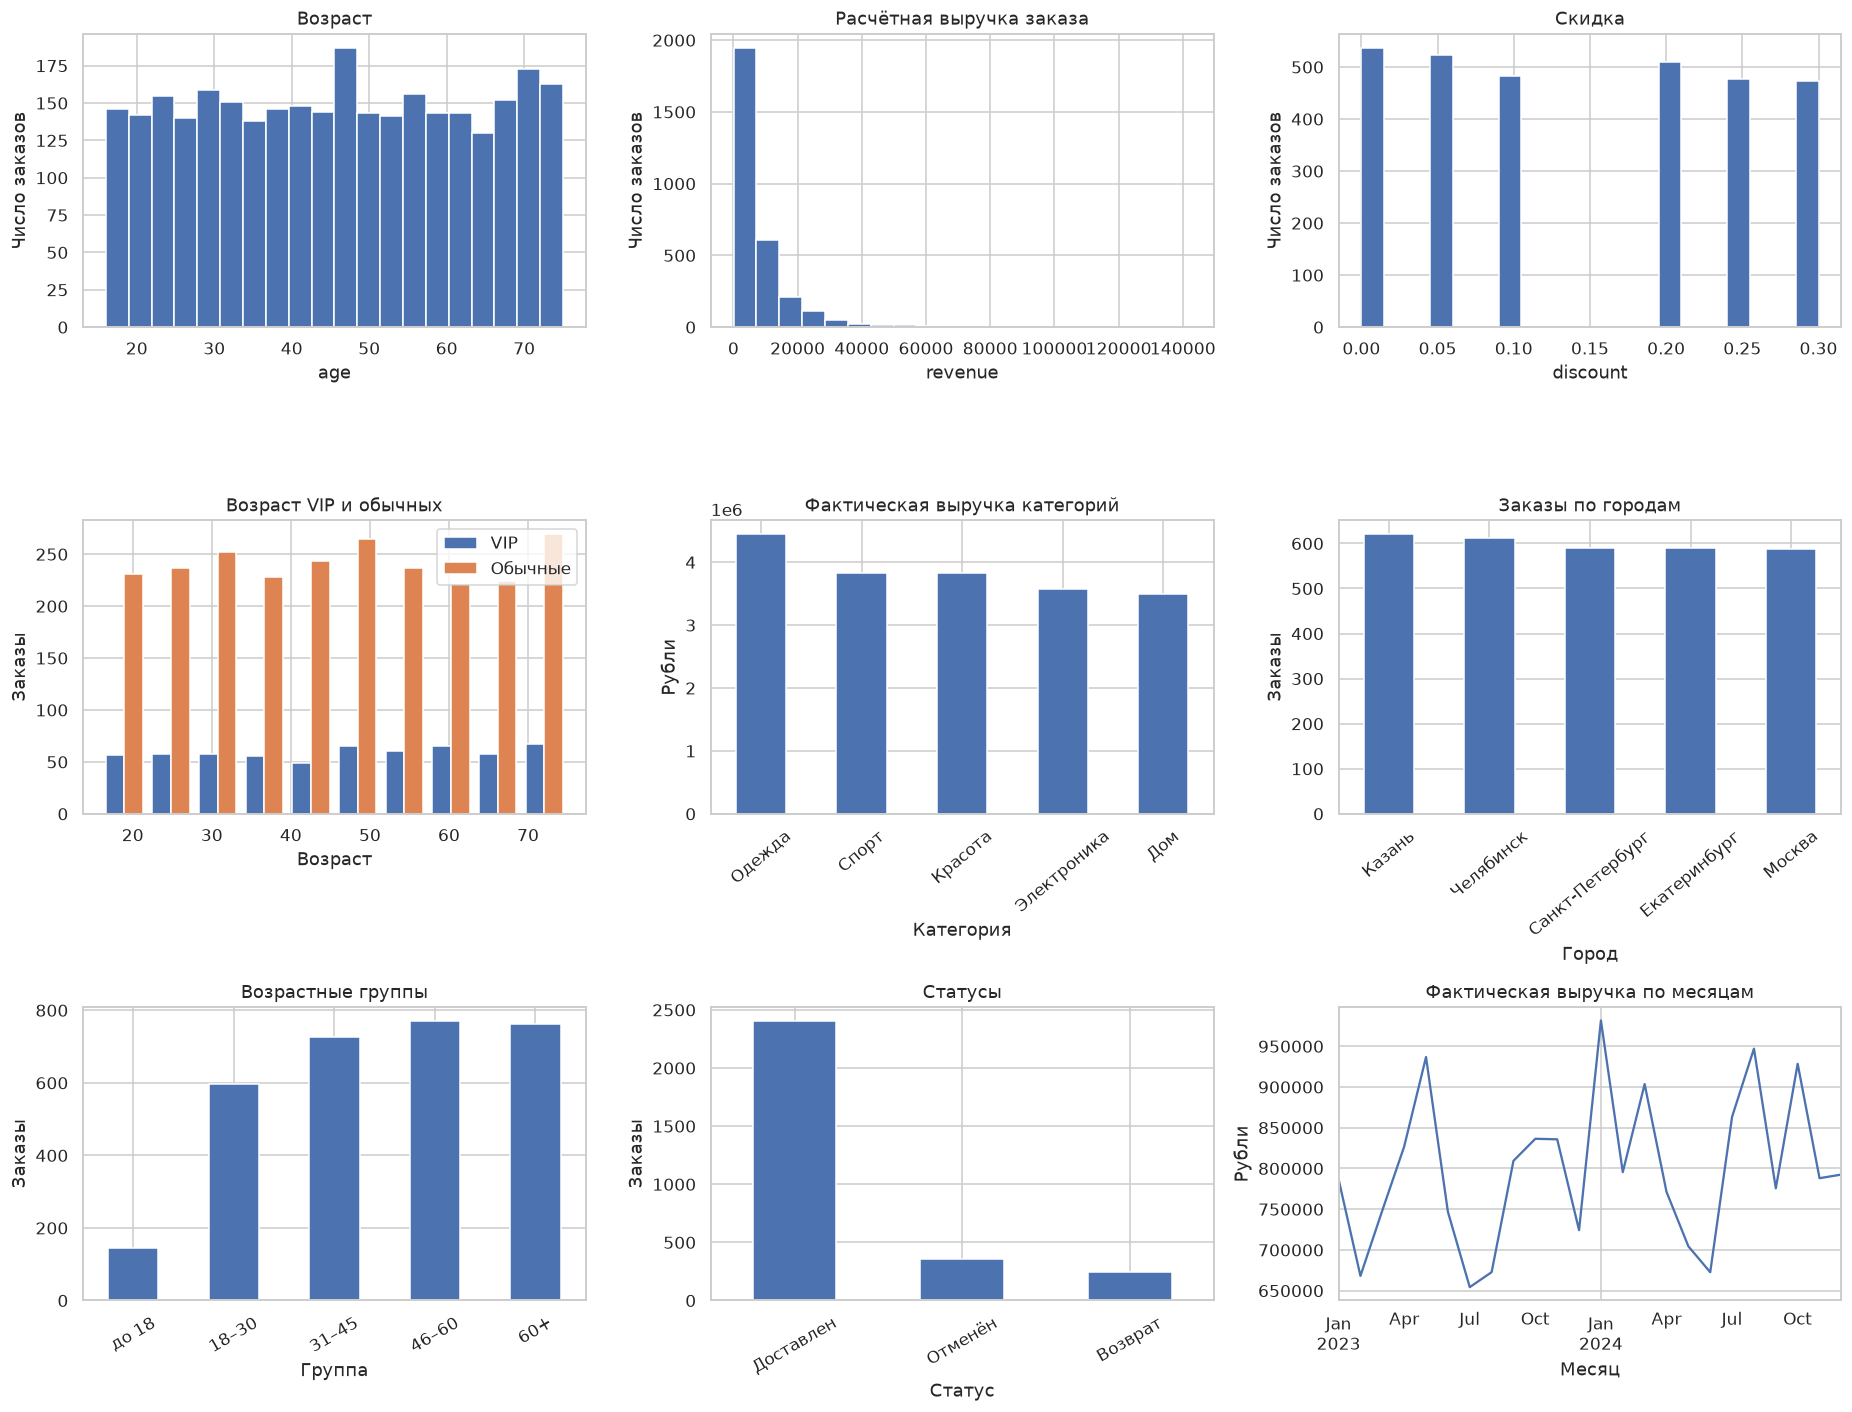

In [6]:
fig,ax=plt.subplots(3,3,figsize=(17,13))
for a,col,title in zip(ax.flat[:3],['age','revenue','discount'],['Возраст','Расчётная выручка заказа','Скидка']):
    a.hist(df[col],bins=20);a.set(title=title,xlabel=col,ylabel='Число заказов')
ax[1,0].hist([df.loc[df.is_vip,'age'],df.loc[~df.is_vip,'age']],label=['VIP','Обычные'],bins=10);ax[1,0].legend();ax[1,0].set(title='Возраст VIP и обычных',xlabel='Возраст',ylabel='Заказы')
actual.plot.bar(ax=ax[1,1],rot=40);ax[1,1].set(title='Фактическая выручка категорий',xlabel='Категория',ylabel='Рубли')
df.city.value_counts().plot.bar(ax=ax[1,2],rot=40);ax[1,2].set(title='Заказы по городам',xlabel='Город',ylabel='Заказы')
df.age_group.value_counts(sort=False).plot.bar(ax=ax[2,0],rot=30);ax[2,0].set(title='Возрастные группы',xlabel='Группа',ylabel='Заказы')
df.status.value_counts().plot.bar(ax=ax[2,1],rot=30);ax[2,1].set(title='Статусы',xlabel='Статус',ylabel='Заказы')
monthly=real.groupby(real.order_date.dt.to_period('M')).revenue.sum();monthly.index=monthly.index.to_timestamp();monthly.plot(ax=ax[2,2]);ax[2,2].set(title='Фактическая выручка по месяцам',xlabel='Месяц',ylabel='Рубли')
show('store_dashboard')

## 6 Мини анализ

In [7]:
vip_share=real.loc[real.is_vip,'revenue'].sum()/real.revenue.sum()
print('Всего заказов:',len(df),'Доставлено:',len(real),'Расчётная сумма всех:',df.revenue.sum(),'Фактическая:',real.revenue.sum(),'Средняя доставленного:',real.revenue.mean())
print('Максимум/минимум категорий:',actual.idxmax(),actual.idxmin(),'Доля VIP:',vip_share)
df['discount_group']=pd.cut(df.discount,[-.001,.1,.2,.31],labels=['0–10%','>10–20%','>20–30%'])
discount_stats=df.groupby('discount_group',observed=True).revenue.agg(['count','mean']);display(discount_stats)
losses=pd.crosstab(df.category,df.status).reindex(columns=['Отменён','Возврат'],fill_value=0);losses['Всего']=losses.sum(axis=1);display(losses)

Всего заказов: 3000 Доставлено: 2403 Расчётная сумма всех: 23992849.4785 Фактическая: 19170545.939 Средняя доставленного: 7977.75528048273
Максимум/минимум категорий: Одежда Дом Доля VIP: 0.19007671247833416


,count,mean
discount_group,,
0–10%,1542,9041.186217
>10–20%,509,7427.773202
>20–30%,949,6607.590908


status,Отменён,Возврат,Всего
category,,,
Дом,68,52,120
Красота,85,53,138
Одежда,62,47,109
Спорт,68,41,109
Электроника,73,48,121


Всего 3000 заказов, из них 2403 доставлены; отмены и возвраты исключены из фактической выручки 19,170,545.94 руб. Средняя выручка доставленного заказа 7977.76 руб. Наибольшая фактическая выручка у категории «Одежда», наименьшая — «Дом». Самое большое число заказов у города «Казань». VIP дают 19.0% фактической выручки. Сравнение скидочных групп наблюдательное: различия среднего чека зависят также от цены и количества, причинный эффект скидки не установлен. Больше всего отмен и возвратов в абсолютных числах у «Красота»; дополнительно нужны доли от заказов категории, анализ маржи и проверка результатов на реальных данных.

## Контрольные вопросы
1. DataFrame — двумерная таблица с именованными столбцами и индексом.
2. loc выбирает по меткам (правая метка среза включается), iloc — по позициям (правая граница исключается).
3. groupby разделяет наблюдения на группы; agg задаёт одно или несколько агрегирований.
4. mean чувствителен к экстремумам, median — центральная порядковая величина.
5. Пропуски находятся isna; методы: удаление, константа, среднее/медиана/мода, прогнозное заполнение.
6. pd.cut разбивает числовой признак на интервалы; value_counts считает частоты; idxmax возвращает индекс первого максимума.
7. Несколько фильтров объединяются &, | и скобками; качество данных проверяется до анализа, чтобы избежать искажённых выводов.
8. revenue — выручка, profit — выручка минус затраты. Отмены и возвраты не являются реализованной выручкой в этой модели.
9. Визуализация обнаруживает распределения и зависимости; Git хранит версии, позволяет видеть изменения и воспроизводить этапы работы.